# Loan Approval Prediction

## Project Overview

This project explores applicant information to identify patterns associated with loan approval and builds machine learning classification models to predict whether a loan application will be approved.

The project covers data inspection, data cleaning, exploratory data analysis, preprocessing, model training, and model evaluation.

## Objectives

- Understand the dataset and its features.
- Identify and handle missing values appropriately.
- Explore patterns associated with loan approval.
- Prepare the data for machine learning.
- Train and compare classification models.
- Evaluate model performance using appropriate metrics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Check the number of rows and columns
df = pd.read_csv("loan_approval_data.csv")
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [3]:
# Check the number of missing values in each column
print("Missing values:\n")
print(df.isnull().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check summary statistics for numerical columns
print("\nSummary statistics:")
display(df.describe())

Missing values:

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

Number of duplicate rows: 0

Summary statistics:


,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


In [4]:
# Check the distribution of the target variable
print("Loan approval counts:")
print(df["Loan_Approved"].value_counts(dropna=False))

print("\nLoan approval percentages:")
print(
    (df["Loan_Approved"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Loan approval counts:
Loan_Approved
No     652
Yes    298
NaN     50
Name: count, dtype: int64

Loan approval percentages:
Loan_Approved
No     65.2
Yes    29.8
NaN     5.0
Name: proportion, dtype: float64


In [5]:
# Remove rows with missing target values
df = df.dropna(subset=["Loan_Approved"]).copy()

# Check the updated dataset and target distribution
print("Dataset shape after removing missing target values:", df.shape)
print("\nLoan approval counts:")
print(df["Loan_Approved"].value_counts())

print("\nMissing target values:", df["Loan_Approved"].isnull().sum())

Dataset shape after removing missing target values: (950, 20)

Loan approval counts:
Loan_Approved
No     652
Yes    298
Name: count, dtype: int64

Missing target values: 0


In [6]:
# Check missing values after removing rows with unknown target labels
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[missing_summary["Missing_Count"] > 0]
missing_summary = missing_summary.sort_values(
    by="Missing_Count", ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
Property_Area,49,5.16
Existing_Loans,49,5.16
Savings,49,5.16
Collateral_Value,49,5.16
Coapplicant_Income,48,5.05
Applicant_ID,48,5.05
Applicant_Income,48,5.05
Credit_Score,48,5.05
Loan_Purpose,48,5.05
Age,48,5.05


In [7]:
# Identify categorical columns
categorical_columns = df.select_dtypes(include="object").columns

# Display the number of unique values in each categorical column
print("Number of unique values in categorical columns:\n")
print(df[categorical_columns].nunique())

# Display sample categories from each categorical column
print("\nUnique categories in each column:\n")

for column in categorical_columns:
    print(f"{column}: {df[column].dropna().unique()}")
    print("-" * 60)

Number of unique values in categorical columns:


C:\Users\DELL\AppData\Local\Temp\ipykernel_9008\4241617105.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns



Employment_Status    4
Marital_Status       2
Loan_Purpose         5
Property_Area        3
Education_Level      2
Gender               2
Employer_Category    5
Loan_Approved        2
dtype: int64

Unique categories in each column:

Employment_Status: <StringArray>
['Salaried', 'Self-employed', 'Contract', 'Unemployed']
Length: 4, dtype: str
------------------------------------------------------------
Marital_Status: <StringArray>
['Married', 'Single']
Length: 2, dtype: str
------------------------------------------------------------
Loan_Purpose: <StringArray>
['Personal', 'Car', 'Business', 'Home', 'Education']
Length: 5, dtype: str
------------------------------------------------------------
Property_Area: <StringArray>
['Urban', 'Semiurban', 'Rural']
Length: 3, dtype: str
------------------------------------------------------------
Education_Level: <StringArray>
['Not Graduate', 'Graduate']
Length: 2, dtype: str
------------------------------------------------------------
Gender: 

Summary statistics for numerical columns:



,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,902.00,902.00,902.00,902.00,903.00,902.00,901.00,903.00,901.00,901.00,903.00,902.00
mean,498.53,10847.02,5061.61,40.04,1.46,675.11,1.95,0.35,9966.30,24701.88,20455.90,48.00
std,290.65,5064.21,2937.41,11.19,1.10,71.33,1.41,0.14,5859.62,14328.91,11511.44,24.26
min,1.00,2009.00,1.00,21.00,0.00,550.00,0.00,0.10,73.00,36.00,1015.00,12.00
25%,243.25,6742.00,2469.75,31.00,1.00,616.00,1.00,0.22,4761.00,12634.00,9772.50,24.00
50%,497.50,10452.50,5143.00,40.00,1.00,677.00,2.00,0.34,9910.00,24059.00,21282.00,48.00
75%,752.75,15174.25,7589.75,49.00,2.00,735.00,3.00,0.48,15052.00,36843.00,30138.50,72.00
max,1000.00,19988.00,9996.00,59.00,3.00,799.00,4.00,0.60,19996.00,49954.00,39995.00,84.00


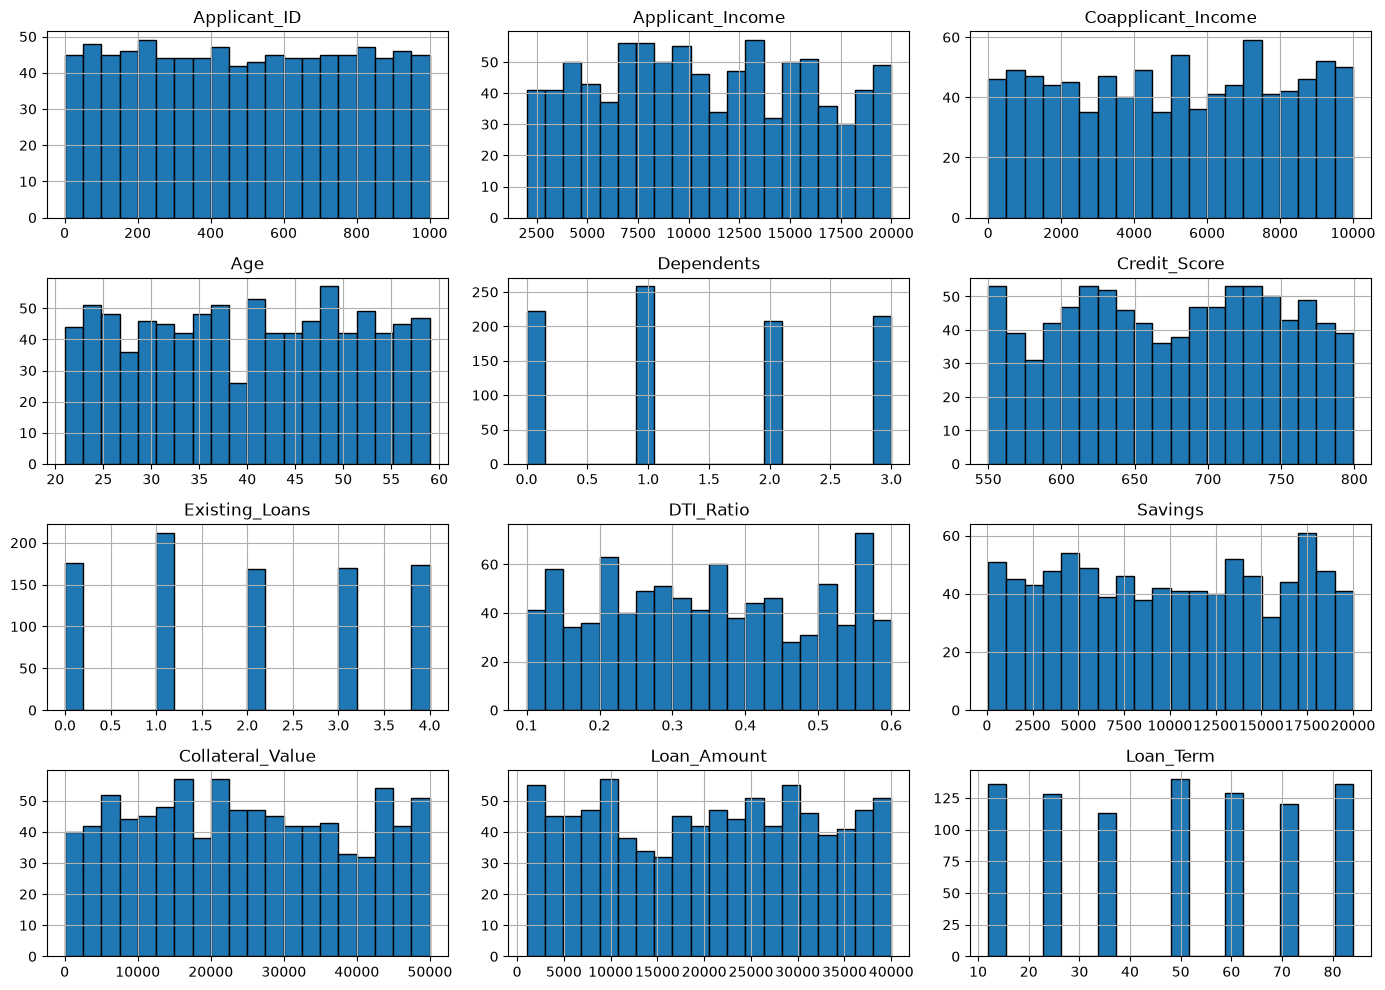

In [8]:
# Identify numerical columns
numerical_columns = df.select_dtypes(include=np.number).columns

# Display summary statistics for numerical features
print("Summary statistics for numerical columns:\n")
display(df[numerical_columns].describe().round(2))

# Visualize the distributions of numerical features
df[numerical_columns].hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

In [9]:
# Check minimum and maximum values in numerical columns
for column in numerical_columns:
    print(
        f"{column}: minimum = {df[column].min()}, "
        f"maximum = {df[column].max()}"
    )

# Check for negative values in numerical columns
print("\nNegative values in numerical columns:")
print((df[numerical_columns] < 0).sum())

Applicant_ID: minimum = 1.0, maximum = 1000.0
Applicant_Income: minimum = 2009.0, maximum = 19988.0
Coapplicant_Income: minimum = 1.0, maximum = 9996.0
Age: minimum = 21.0, maximum = 59.0
Dependents: minimum = 0.0, maximum = 3.0
Credit_Score: minimum = 550.0, maximum = 799.0
Existing_Loans: minimum = 0.0, maximum = 4.0
DTI_Ratio: minimum = 0.1, maximum = 0.6
Savings: minimum = 73.0, maximum = 19996.0
Collateral_Value: minimum = 36.0, maximum = 49954.0
Loan_Amount: minimum = 1015.0, maximum = 39995.0
Loan_Term: minimum = 12.0, maximum = 84.0

Negative values in numerical columns:
Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Age                   0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
dtype: int64


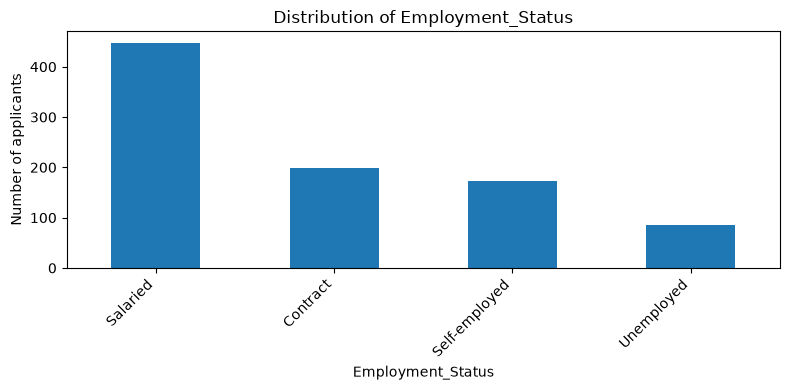

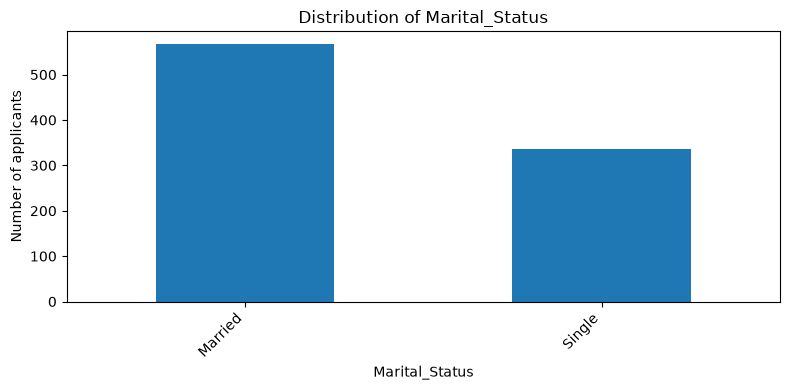

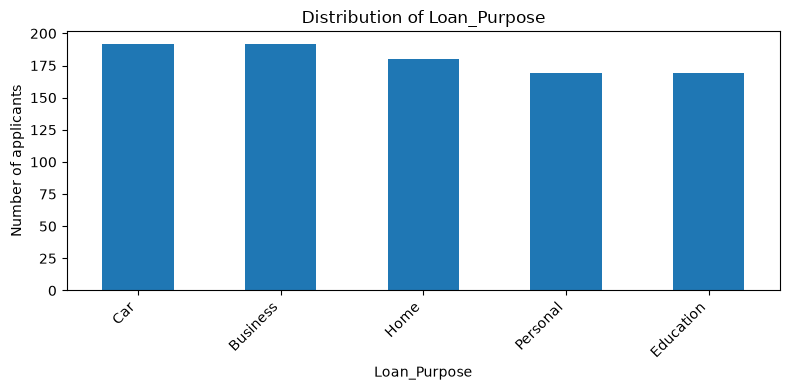

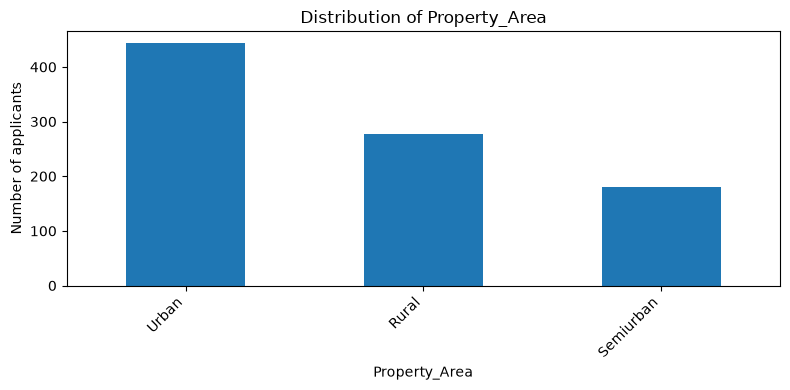

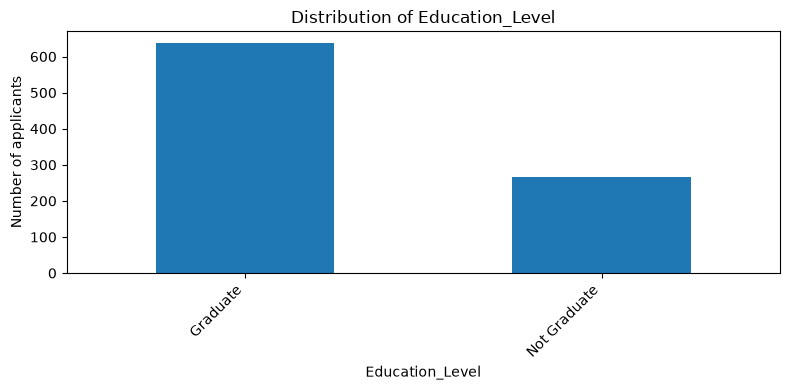

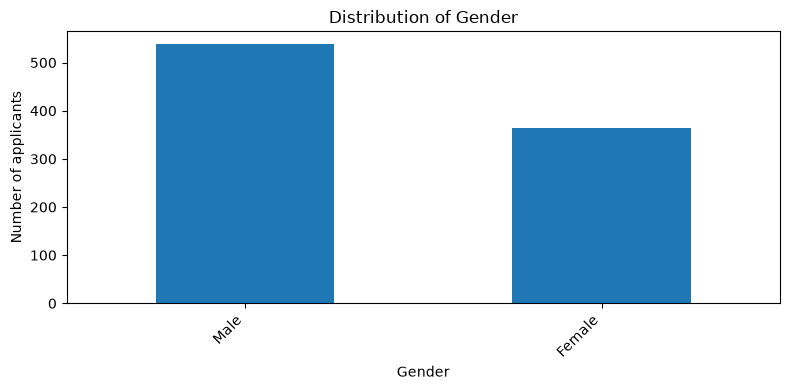

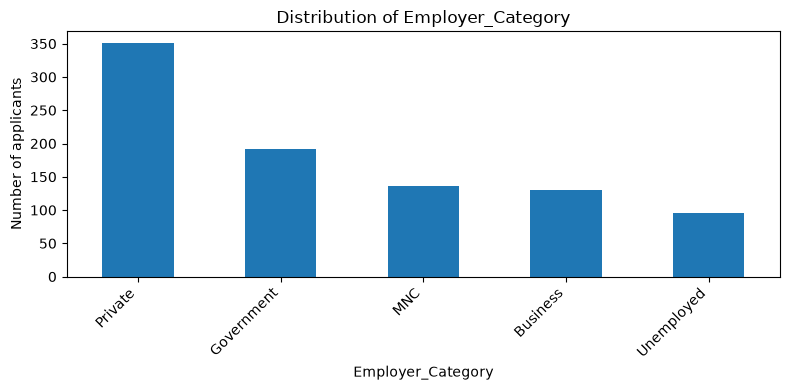

In [10]:
# Plot the distribution of categorical features, excluding the target
categorical_features = [
    column for column in categorical_columns
    if column != "Loan_Approved"
]

for column in categorical_features:
    plt.figure(figsize=(8, 4))
    df[column].value_counts().plot(kind="bar")
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of applicants")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [11]:
# Remove the applicant ID because it is an identifier, not a predictive feature
df = df.drop(columns=["Applicant_ID"])

# Separate the input features from the target
X = df.drop(columns=["Loan_Approved"])
y = df["Loan_Approved"]

# Identify numerical and categorical input columns
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

# Check the prepared data
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nNumerical features:", numerical_features)
print("\nCategorical features:", categorical_features)
print("\nMissing target values:", y.isnull().sum())

Feature matrix shape: (950, 18)
Target shape: (950,)

Numerical features: ['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term']

Categorical features: ['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender', 'Employer_Category']

Missing target values: 0


C:\Users\DELL\AppData\Local\Temp\ipykernel_9008\948790981.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include="object").columns.tolist()


In [12]:
from sklearn.model_selection import train_test_split

# Split the data while preserving the target class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the resulting dataset sizes and target distributions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (760, 18)
Testing features: (190, 18)

Training target distribution:
Loan_Approved
No     0.687
Yes    0.313
Name: proportion, dtype: float64

Testing target distribution:
Loan_Approved
No     0.684
Yes    0.316
Name: proportion, dtype: float64


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocess numerical features: fill missing values and scale
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features: fill missing values and encode categories
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each feature type
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Combine preprocessing and Logistic Regression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Train the model using only the training data
logistic_model.fit(X_train, y_train)

# Predict loan approval on the unseen test data
y_pred_lr = logistic_model.predict(X_test)

# Evaluate the model
print("Logistic Regression Results")
print("----------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 3))
print("Precision:", round(precision_score(y_test, y_pred_lr, pos_label="Yes"), 3))
print("Recall:", round(recall_score(y_test, y_pred_lr, pos_label="Yes"), 3))
print("F1-score:", round(f1_score(y_test, y_pred_lr, pos_label="Yes"), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr, labels=["No", "Yes"]))

Logistic Regression Results
----------------------------
Accuracy: 0.884
Precision: 0.852
Recall: 0.767
F1-score: 0.807

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.94      0.92       130
         Yes       0.85      0.77      0.81        60

    accuracy                           0.88       190
   macro avg       0.87      0.85      0.86       190
weighted avg       0.88      0.88      0.88       190

Confusion Matrix:
[[122   8]
 [ 14  46]]


In [15]:
from sklearn.neighbors import KNeighborsClassifier

# Combine preprocessing and KNN
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train and predict
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

# Evaluate KNN using the same metrics
print("KNN Results")
print("-----------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_knn), 3))
print("Precision:", round(precision_score(y_test, y_pred_knn, pos_label="Yes"), 3))
print("Recall:", round(recall_score(y_test, y_pred_knn, pos_label="Yes"), 3))
print("F1-score:", round(f1_score(y_test, y_pred_knn, pos_label="Yes"), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn, labels=["No", "Yes"]))

KNN Results
-----------
Accuracy: 0.8
Precision: 0.696
Recall: 0.65
F1-score: 0.672

Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.87      0.86       130
         Yes       0.70      0.65      0.67        60

    accuracy                           0.80       190
   macro avg       0.77      0.76      0.76       190
weighted avg       0.80      0.80      0.80       190

Confusion Matrix:
[[113  17]
 [ 21  39]]


In [16]:
# Preprocess numerical and categorical features
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    sparse_threshold=0
)

In [17]:
from sklearn.naive_bayes import GaussianNB

# Combine preprocessing and Gaussian Naive Bayes
nb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GaussianNB())
])

# Train and predict
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

# Evaluate the model
print("Gaussian Naive Bayes Results")
print("----------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_nb), 3))
print("Precision:", round(precision_score(y_test, y_pred_nb, pos_label="Yes"), 3))
print("Recall:", round(recall_score(y_test, y_pred_nb, pos_label="Yes"), 3))
print("F1-score:", round(f1_score(y_test, y_pred_nb, pos_label="Yes"), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb, labels=["No", "Yes"]))

Gaussian Naive Bayes Results
----------------------------
Accuracy: 0.874
Precision: 0.833
Recall: 0.75
F1-score: 0.789

Classification Report:
              precision    recall  f1-score   support

          No       0.89      0.93      0.91       130
         Yes       0.83      0.75      0.79        60

    accuracy                           0.87       190
   macro avg       0.86      0.84      0.85       190
weighted avg       0.87      0.87      0.87       190

Confusion Matrix:
[[121   9]
 [ 15  45]]


In [18]:
# Compare the three models using the same evaluation metrics
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Gaussian Naive Bayes"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_nb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, pos_label="Yes"),
        precision_score(y_test, y_pred_knn, pos_label="Yes"),
        precision_score(y_test, y_pred_nb, pos_label="Yes")
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, pos_label="Yes"),
        recall_score(y_test, y_pred_knn, pos_label="Yes"),
        recall_score(y_test, y_pred_nb, pos_label="Yes")
    ],
    "F1-score": [
        f1_score(y_test, y_pred_lr, pos_label="Yes"),
        f1_score(y_test, y_pred_knn, pos_label="Yes"),
        f1_score(y_test, y_pred_nb, pos_label="Yes")
    ]
})

# Display results from highest to lowest F1-score
results = results.sort_values("F1-score", ascending=False)
display(results.round(3).reset_index(drop=True))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.884,0.852,0.767,0.807
1,Gaussian Naive Bayes,0.874,0.833,0.750,0.789
2,KNN,0.800,0.696,0.650,0.672


In [19]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Use five stratified folds to preserve class proportions
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate each complete pipeline on the training data
models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Gaussian Naive Bayes": nb_model
}

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std()
    })

cv_summary = pd.DataFrame(cv_results)
display(cv_summary.round(3))

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Recall Mean,F1 Mean,F1 Std
0,Logistic Regression,0.857,0.023,NaN,NaN,NaN,NaN
1,KNN,0.818,0.019,NaN,NaN,NaN,NaN
2,Gaussian Naive Bayes,0.857,0.010,NaN,NaN,NaN,NaN


In [20]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# Preserve class proportions across five folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Explicitly treat "Yes" as the positive class
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label="Yes", zero_division=0),
    "recall": make_scorer(recall_score, pos_label="Yes", zero_division=0),
    "f1": make_scorer(f1_score, pos_label="Yes", zero_division=0)
}

models = {
    "Logistic Regression": logistic_model,
    "KNN": knn_model,
    "Gaussian Naive Bayes": nb_model
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std()
    })

cv_summary = pd.DataFrame(cv_results)
display(cv_summary.round(3))

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Recall Mean,F1 Mean,F1 Std
0,Logistic Regression,0.857,0.023,0.800,0.727,0.760,0.042
1,KNN,0.818,0.019,0.727,0.673,0.696,0.047
2,Gaussian Naive Bayes,0.857,0.010,0.823,0.697,0.753,0.014


In [21]:

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

# Treat "Yes" (loan approved) as the positive class
f1_scorer = make_scorer(
    f1_score,
    pos_label="Yes",
    zero_division=0
)

grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    scoring=f1_scorer,
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1:", round(grid_search.best_score_, 3))

best_logistic_model = grid_search.best_estimator_


Best parameters: {'classifier__C': 10}
Best cross-validation F1: 0.76


In [22]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict on the held-out test set
y_pred_tuned = best_logistic_model.predict(X_test)

print("Tuned Logistic Regression Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 3))
print("Precision (Yes):", round(
    precision_score(y_test, y_pred_tuned, pos_label="Yes"), 3
))
print("Recall (Yes):", round(
    recall_score(y_test, y_pred_tuned, pos_label="Yes"), 3
))
print("F1-score (Yes):", round(
    f1_score(y_test, y_pred_tuned, pos_label="Yes"), 3
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, zero_division=0))

print("Confusion Matrix (No, Yes):")
print(confusion_matrix(y_test, y_pred_tuned, labels=["No", "Yes"]))


Tuned Logistic Regression Results
Accuracy: 0.879
Precision (Yes): 0.836
Recall (Yes): 0.767
F1-score (Yes): 0.8

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.93      0.91       130
         Yes       0.84      0.77      0.80        60

    accuracy                           0.88       190
   macro avg       0.87      0.85      0.86       190
weighted avg       0.88      0.88      0.88       190

Confusion Matrix (No, Yes):
[[121   9]
 [ 14  46]]


In [23]:

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

knn_param_grid = {
    "classifier__n_neighbors": [3, 5, 7, 9, 11, 15]
}

f1_scorer = make_scorer(
    f1_score,
    pos_label="Yes",
    zero_division=0
)

knn_grid_search = GridSearchCV(
    estimator=knn_model,
    param_grid=knn_param_grid,
    scoring=f1_scorer,
    cv=cv,
    n_jobs=-1
)

knn_grid_search.fit(X_train, y_train)

print("Best KNN parameters:", knn_grid_search.best_params_)
print(
    "Best cross-validation F1:",
    round(knn_grid_search.best_score_, 3)
)

best_knn_model = knn_grid_search.best_estimator_


Best KNN parameters: {'classifier__n_neighbors': 15}
Best cross-validation F1: 0.721


In [24]:
y_pred_knn_tuned = best_knn_model.predict(X_test)

print("Tuned KNN Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_knn_tuned), 3))
print("Precision (Yes):", round(
    precision_score(y_test, y_pred_knn_tuned, pos_label="Yes"), 3
))
print("Recall (Yes):", round(
    recall_score(y_test, y_pred_knn_tuned, pos_label="Yes"), 3
))
print("F1-score (Yes):", round(
    f1_score(y_test, y_pred_knn_tuned, pos_label="Yes"), 3
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_knn_tuned, zero_division=0
))

print("Confusion Matrix (No, Yes):")
print(confusion_matrix(
    y_test, y_pred_knn_tuned, labels=["No", "Yes"]
))


Tuned KNN Results
Accuracy: 0.858
Precision (Yes): 0.824
Recall (Yes): 0.7
F1-score (Yes): 0.757

Classification Report:
              precision    recall  f1-score   support

          No       0.87      0.93      0.90       130
         Yes       0.82      0.70      0.76        60

    accuracy                           0.86       190
   macro avg       0.85      0.82      0.83       190
weighted avg       0.86      0.86      0.85       190

Confusion Matrix (No, Yes):
[[121   9]
 [ 18  42]]


In [25]:
final_predictions = {
    "Logistic Regression (Original)": y_pred_lr,
    "Logistic Regression (Tuned)": y_pred_tuned,
    "Gaussian Naive Bayes": y_pred_nb,
    "KNN (Original)": y_pred_knn,
    "KNN (Tuned)": y_pred_knn_tuned
}

comparison_rows = []

for model_name, predictions in final_predictions.items():
    comparison_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Yes)": precision_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "Recall (Yes)": recall_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "F1-score (Yes)": f1_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        )
    })

final_comparison = pd.DataFrame(comparison_rows)
final_comparison = final_comparison.sort_values(
    by="F1-score (Yes)", ascending=False
).reset_index(drop=True)

display(final_comparison.round(3))


,Model,Accuracy,Precision (Yes),Recall (Yes),F1-score (Yes)
0,Logistic Regression (Original),0.884,0.852,0.767,0.807
1,Logistic Regression (Tuned),0.879,0.836,0.767,0.800
2,Gaussian Naive Bayes,0.874,0.833,0.750,0.789
3,KNN (Tuned),0.858,0.824,0.700,0.757
4,KNN (Original),0.800,0.696,0.650,0.672


##  Final Findings and Conclusions

### Model Comparison
Five model versions were evaluated on the same held-out test set: original Logistic Regression, tuned Logistic Regression, Gaussian Naive Bayes, original KNN, and tuned KNN.

The original Logistic Regression achieved the strongest test-set results among the evaluated models, with an accuracy of 0.884 and an F1-score of 0.807 for the loan-approved class (`Yes`).

Hyperparameter tuning improved KNN's test-set F1-score from 0.672 to 0.757. However, tuned KNN did not outperform the original Logistic Regression. Tuning Logistic Regression did not improve its held-out test-set results.

### Interpretation
The original Logistic Regression correctly identified 46 of the 60 applicants whose loans were approved, giving a recall of 0.767 for the `Yes` class. It also incorrectly predicted approval for 8 applicants whose actual outcome was `No`.

These results illustrate why model evaluation should consider precision, recall, and F1-score in addition to accuracy.

### Limitations
- The evaluation uses one train/test split and cross-validation on the training set. Results may differ on other data.
- The dataset's provenance has not yet been established.
- Model performance alone does not establish that the model is suitable for real-world lending decisions.
- The analysis does not establish causal relationships or assess fairness across applicant groups.

### Conclusion
Among the evaluated models, the original Logistic Regression performed best on the held-out test set according to F1-score for the approved-loan class. Further validation on independent data would be necessary before drawing conclusions about performance beyond this dataset.